# 01 - Exploratory Data Analysis

## 1. Load data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
PALETTE = ['#9575CD', '#F06292', '#BA68C8', '#7E57C2', '#EC407A', '#CE93D8', '#B39DDB', '#AD1457']
sns.set_theme(style='whitegrid', palette=PALETTE)

DATA_PATH = '../data/trips_all_cities_master.csv'
trips = pd.read_csv(DATA_PATH)
trips['date'] = pd.to_datetime(trips['date'])

In [3]:
trips.head()

,city,time_start,time_end,lat_start,lng_start,name_start,lat_end,lng_end,name_end,duration_s,distance_m,speed_kmh,date,hour,weekday,day_type,month
0,Badalona,2025-04-01T00:00:30+0200,2025-04-01T00:12:33+0200,41.45691,2.24451,Molí de la Torre - Joan Junceda,41.46462,2.25024,Pomar,723,1068.8,5.32,2025-04-01,0,Tuesday,Weekday,2025-04
1,Badalona,2025-04-01T01:16:48+0200,2025-04-01T01:26:50+0200,41.43463,2.22676,METRO Sant Roc,41.43412,2.21603,METRO Artigues | Sant Adrià,602,1195.8,7.15,2025-04-01,1,Tuesday,Weekday,2025-04
2,Badalona,2025-04-01T03:59:25+0200,2025-04-01T04:07:27+0200,41.45545,2.25743,Canyadó,41.45293,2.24325,Martí Pujol - Pau Rodon,482,1603.2,11.97,2025-04-01,3,Tuesday,Weekday,2025-04
3,Badalona,2025-04-01T03:59:25+0200,2025-04-01T04:13:29+0200,41.45545,2.25743,Canyadó,41.44828,2.24220,METRO Badalona Pompeu Fabra,844,1873.6,7.99,2025-04-01,3,Tuesday,Weekday,2025-04
4,Badalona,2025-04-01T05:11:41+0200,2025-04-01T05:19:43+0200,41.45825,2.23579,La Ciència,41.44613,2.24906,RENFE Badalona,482,1999.9,14.94,2025-04-01,5,Tuesday,Weekday,2025-04


## 2. Shape, types and missing values

In [4]:
# Confirms the dataset size (10k+ rows requirement), variable types and whether imputation is needed
print('Shape:', trips.shape)
trips.info()

Shape: (393182, 17)
<class 'pandas.DataFrame'>
RangeIndex: 393182 entries, 0 to 393181
Data columns (total 17 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   city        393182 non-null  str           
 1   time_start  393182 non-null  str           
 2   time_end    393182 non-null  str           
 3   lat_start   393182 non-null  float64       
 4   lng_start   393182 non-null  float64       
 5   name_start  393182 non-null  str           
 6   lat_end     393182 non-null  float64       
 7   lng_end     393182 non-null  float64       
 8   name_end    393182 non-null  str           
 9   duration_s  393182 non-null  int64         
 10  distance_m  393182 non-null  float64       
 11  speed_kmh   393182 non-null  float64       
 12  date        393182 non-null  datetime64[us]
 13  hour        393182 non-null  int64         
 14  weekday     393182 non-null  str           
 15  day_type    393182 non-null  str          

In [5]:
print('Missing values per column:')
print(trips.isna().sum())
print('\nExact duplicate rows:', trips.duplicated().sum())

Missing values per column:
city          0
time_start    0
time_end      0
lat_start     0
lng_start     0
name_start    0
lat_end       0
lng_end       0
name_end      0
duration_s    0
distance_m    0
speed_kmh     0
date          0
hour          0
weekday       0
day_type      0
month         0
dtype: int64

Exact duplicate rows: 0


In [6]:
check_cols = ['duration_s', 'distance_m', 'speed_kmh', 'lat_start', 'lng_start', 'lat_end', 'lng_end']
(trips[check_cols] == 0).sum()

duration_s    0
distance_m    0
speed_kmh     0
lat_start     0
lng_start     0
lat_end       0
lng_end       0
dtype: int64

## 3. Summary statistics

In [7]:
trips.describe().T.round(2) # Checks all numeric columns to find impossible values with min/max 

,count,mean,min,25%,50%,75%,max,std
lat_start,393182.0,48.455559,41.43158,49.2039,49.78821,49.84096,50.58778,2.932358
lng_start,393182.0,14.023302,-5.611,8.71921,18.16684,18.28801,18.52777,7.372832
lat_end,393182.0,48.455463,41.43158,49.2039,49.78976,49.84103,50.58778,2.93249
lng_end,393182.0,14.023319,-5.611,8.72072,18.16823,18.28801,18.52776,7.372775
duration_s,393182.0,820.696922,151.0,481.0,603.0,845.0,14399.0,983.173099
distance_m,393182.0,1616.56035,50.2,865.0,1341.6,2046.4,24791.1,1143.696056
speed_kmh,393182.0,8.339319,0.01,5.91,8.13,10.59,29.99,3.676357
date,393182,2024-10-31 19:47:01.514717,2024-08-01 00:00:00,2024-08-24 00:00:00,2024-09-20 00:00:00,2025-01-02 00:00:00,2025-05-31 00:00:00,NaN
hour,393182.0,14.33748,0.0,11.0,15.0,18.0,23.0,5.054701


In [ ]:
# Summary table for report
# Here we check only continuous variables because mean and variance are meaningful for them. Hour, weekday and coordinates were excluded because they do not represent quantities but rather categorical information or locations

main_cols = ['duration_s', 'distance_m', 'speed_kmh']  
summary = trips[main_cols].describe().T
summary['variance'] = trips[main_cols].var()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,variance
duration_s,393182.0,820.70,983.17,151.00,481.00,603.00,845.00,14399.00,966629.34
distance_m,393182.0,1616.56,1143.70,50.20,865.00,1341.60,2046.40,24791.10,1308040.67
speed_kmh,393182.0,8.34,3.68,0.01,5.91,8.13,10.59,29.99,13.52


In [9]:
trips.describe(include='object').T

C:\Users\Наташа Ким\AppData\Local\Temp\ipykernel_5352\3946086585.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  trips.describe(include='object').T


,count,unique,top,freq
city,393182,8,Ostrava,133982
time_start,393182,198605,2024-10-01T15:53:10+0200,19
time_end,393182,197511,2024-08-13T22:05:21+0200,82
name_start,393182,4335,MOAP-Nová Karolina,3623
name_end,393182,4923,RENFE Badalona,3490
weekday,393182,7,Tuesday,65585
day_type,393182,2,Weekday,308826
month,393182,8,2024-08,129930


## 4. Trips per city

In [10]:
#Shows how balanced the cities are and which periods each city covers 
print(trips['city'].value_counts())
print()
print(trips.groupby('city')['date'].agg(['min', 'max']))

city
Ostrava          133982
Brno              48242
Opava             40864
Havirov           38602
Badalona          38155
Frankfurt         33367
Frydek-Mistek     32798
Leon              27172
Name: count, dtype: int64

                     min        max
city                               
Badalona      2025-04-01 2025-05-31
Brno          2024-08-01 2024-10-31
Frankfurt     2025-01-01 2025-03-31
Frydek-Mistek 2024-08-01 2024-10-31
Havirov       2024-08-01 2024-10-31
Leon          2025-04-01 2025-05-31
Opava         2024-08-01 2024-10-31
Ostrava       2024-08-01 2024-10-31


## 5. Distributions

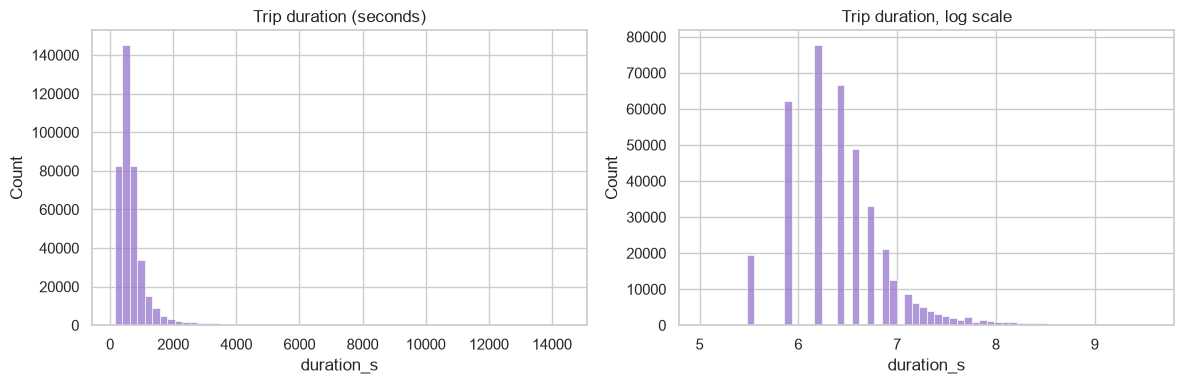

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(trips['duration_s'], bins=60, ax=axes[0])
axes[0].set_title('Trip duration (seconds)')
sns.histplot(np.log1p(trips['duration_s']), bins=60, ax=axes[1])
axes[1].set_title('Trip duration, log scale')
plt.tight_layout()
plt.show()

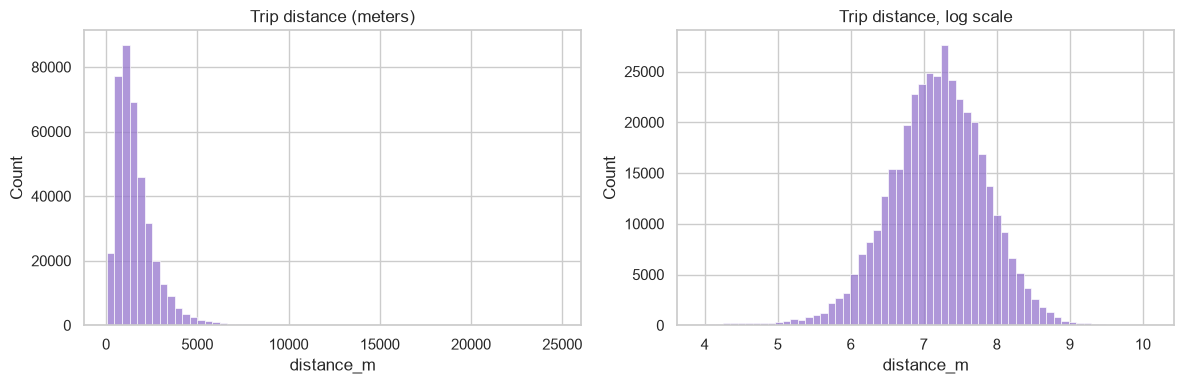

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(trips['distance_m'], bins=60, ax=axes[0])
axes[0].set_title('Trip distance (meters)')
sns.histplot(np.log1p(trips['distance_m']), bins=60, ax=axes[1])
axes[1].set_title('Trip distance, log scale')
plt.tight_layout()
plt.show()

In [13]:
print(trips['duration_s'].quantile([0.5, 0.9, 0.95, 0.99, 0.999]))
print('Trips > 1 hour:', (trips['duration_s'] > 3600).sum())
print('Share > 1 hour, %:', round((trips['duration_s'] > 3600).mean() * 100, 2))
print('Speed < 1 km/h:', (trips['speed_kmh'] < 1).sum())
print('Distance < 100 m:', (trips['distance_m'] < 100).sum())

0.500      603.000
0.900     1324.000
0.950     1814.000
0.990     5317.000
0.999    12530.819
Name: duration_s, dtype: float64
Trips > 1 hour: 7148
Share > 1 hour, %: 1.82
Speed < 1 km/h: 7020
Distance < 100 m: 1271


In [14]:
print((trips['duration_s'] % 120).value_counts().head(10))

duration_s
2     85195
3     69821
4     51461
1     51340
5     36920
6     25469
7     17435
8     11243
9      7471
10     5134
Name: count, dtype: int64


In [15]:
long_trip = trips['duration_s'] > 3600
slow_trip = trips['speed_kmh'] < 1
print('Both long and slow:', (long_trip & slow_trip).sum())

Both long and slow: 3471


In [16]:
slow = trips[trips['speed_kmh'] < 1]
same_station = (slow['name_start'] == slow['name_end'])
print('Slow trips:', len(slow))
print('Of them, same start and end station:', same_station.sum())
print('Share, %:', round(same_station.mean() * 100, 1))

Slow trips: 7020
Of them, same start and end station: 246
Share, %: 3.5


In [17]:
slow = trips[trips['speed_kmh'] < 1]
print(slow[['duration_s', 'distance_m']].describe().round(0))

       duration_s  distance_m
count      7020.0      7020.0
mean       4707.0       686.0
std        3756.0       625.0
min         193.0        50.0
25%        1690.0       213.0
50%        3506.0       494.0
75%        7098.0       958.0
max       14399.0      3820.0


## 6. Demand patterns over time

### 6.1 Trips by hour of day

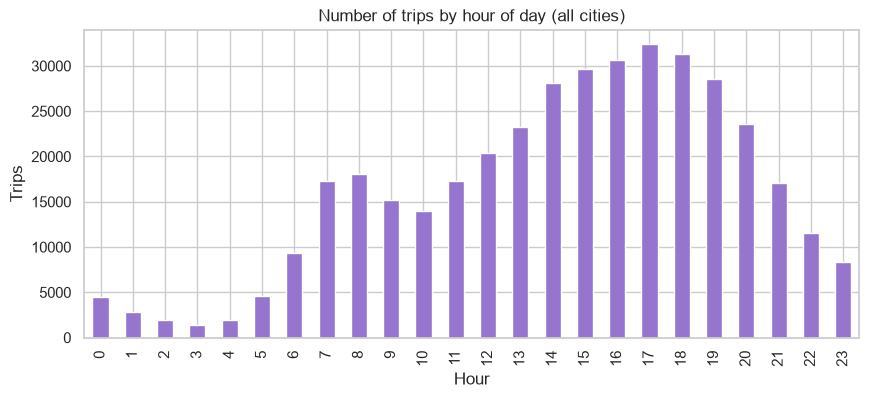

In [18]:
by_hour = trips.groupby('hour').size()
by_hour.plot(kind='bar', figsize=(10, 4))
plt.title('Number of trips by hour of day (all cities)')
plt.xlabel('Hour')
plt.ylabel('Trips')
plt.show()

### 6.2 Weekday vs weekend profile

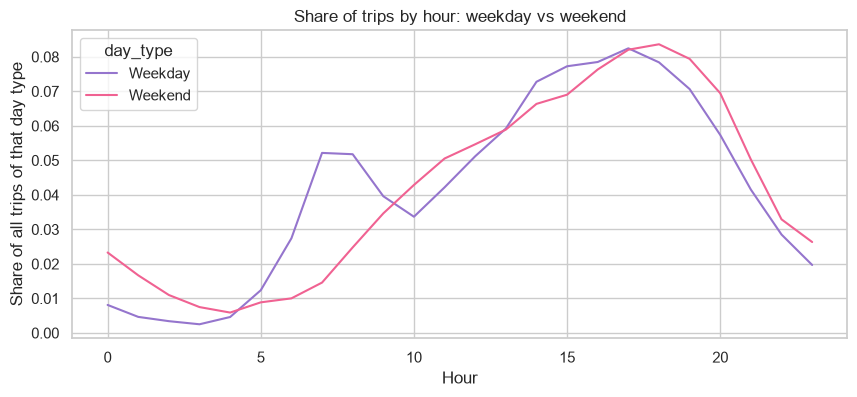

In [19]:
profile = trips.groupby(['day_type', 'hour']).size().unstack(0)
share = profile / profile.sum()
share.plot(figsize=(10, 4))
plt.title('Share of trips by hour: weekday vs weekend')
plt.xlabel('Hour')
plt.ylabel('Share of all trips of that day type')
plt.show()

### 6.3 Average trips per weekday

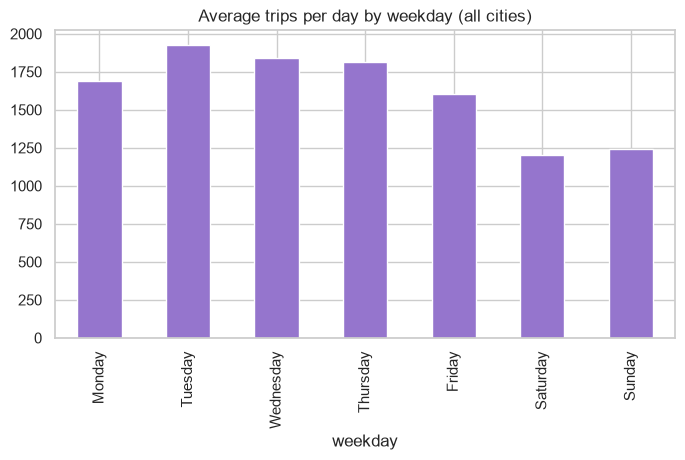

In [20]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily = trips.groupby('date').size()
daily_df = daily.to_frame('trips')
daily_df['weekday'] = daily_df.index.day_name()
avg_by_weekday = daily_df.groupby('weekday')['trips'].mean().reindex(order) #orders the weekdays in a more natural way than alphabetical
avg_by_weekday.plot(kind='bar', figsize=(8, 4), color='#9575CD')
plt.title('Average trips per day by weekday (all cities)')
plt.show()

## 7. Demand by city

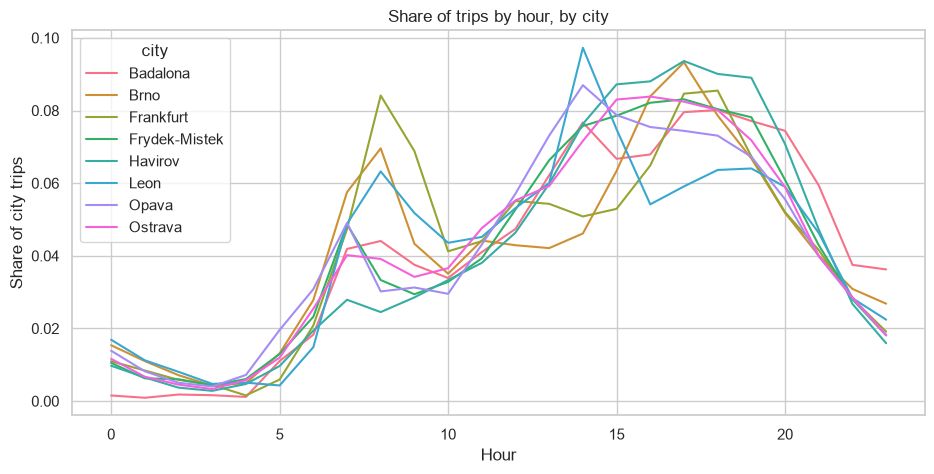

In [21]:
hourly_city = trips.groupby(['city', 'hour']).size().unstack(0)
share_city = hourly_city / hourly_city.sum()
share_city.plot(figsize=(11, 5), color=sns.color_palette('husl', 8))
plt.title('Share of trips by hour, by city')
plt.xlabel('Hour')
plt.ylabel('Share of city trips')
plt.show()     

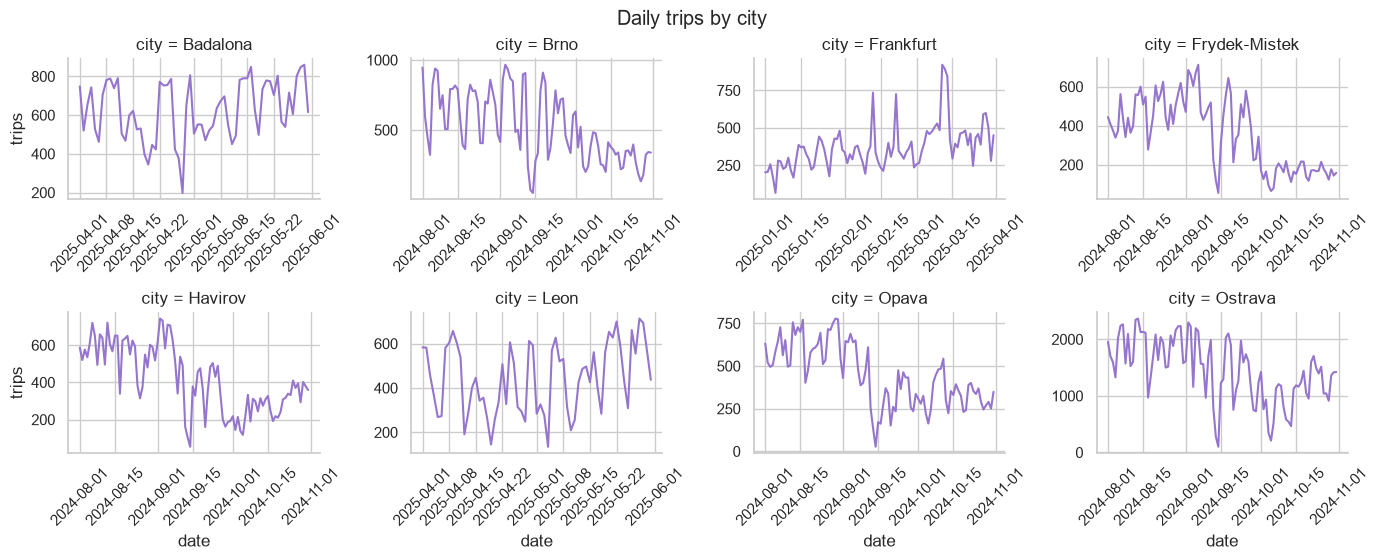

In [22]:
daily_city = trips.groupby(['city', 'date']).size().reset_index(name='trips')

g = sns.relplot(data=daily_city, x='date', y='trips', col='city', col_wrap=4,
                kind='line', height=2.5, aspect=1.4, color='#9575CD',
                facet_kws={'sharey': False, 'sharex': False})
g.fig.subplots_adjust(hspace=0.8)
g.set_xticklabels(rotation=45)
g.fig.suptitle('Daily trips by city', y=1.02)
plt.show()

In [23]:
low_days = daily_city.loc[daily_city.groupby('city')['trips'].idxmin()]
print(low_days)

              city       date  trips
27        Badalona 2025-04-28    198
105           Brno 2024-09-14     51
157      Frankfurt 2025-01-05     66
287  Frydek-Mistek 2024-09-14     56
379        Havirov 2024-09-14     54
460           Leon 2025-05-04    135
532          Opava 2024-09-14     27
624        Ostrava 2024-09-14    101


## 8. Dockless origins
The dataset description says 2-3% of origins are dockless drop-offs (name_start = "BIKE <id>"). This checks it.

In [24]:
dockless = trips['name_start'].str.startswith('BIKE ')
print('Share of dockless origins:', dockless.mean().round(3))
print('Unique dockless names:', trips.loc[dockless, 'name_start'].nunique())
print('Unique docked stations:', trips.loc[~dockless, 'name_start'].nunique())

Share of dockless origins: 0.045
Unique dockless names: 3139
Unique docked stations: 1196


In [25]:
dockless = trips['name_start'].str.startswith('BIKE ')
print(dockless.groupby(trips['city']).mean().round(3))

city
Badalona         0.000
Brno             0.035
Frankfurt        0.294
Frydek-Mistek    0.033
Havirov          0.027
Leon             0.015
Opava            0.022
Ostrava          0.021
Name: name_start, dtype: float64
